In [1]:
import pandas as pd, glob, os

frames = []
for f in glob.glob("DATA/*.csv"):
    city, period = os.path.basename(f).replace(".csv", "").split("_")
    df = pd.read_csv(f)
    df["city"] = city
    df["is_weekend"] = int(period == "weekends")
    frames.append(df)

data = pd.concat(frames, ignore_index=True)
data = data.drop(columns=[c for c in data.columns if c.startswith("Unnamed")])
print(data.shape)
data.head()

(51707, 21)


,realSum,room_type,room_shared,room_private,person_capacity,host_is_superhost,multi,biz,cleanliness_rating,guest_satisfaction_overall,...,dist,metro_dist,attr_index,attr_index_norm,rest_index,rest_index_norm,lng,lat,city,is_weekend
0,194.033698,Private room,False,True,2.0,False,1,0,10.0,93.0,...,5.022964,2.539380,78.690379,4.166708,98.253896,6.846473,4.90569,52.41772,amsterdam,0
1,344.245776,Private room,False,True,4.0,False,0,0,8.0,85.0,...,0.488389,0.239404,631.176378,33.421209,837.280757,58.342928,4.90005,52.37432,amsterdam,0
2,264.101422,Private room,False,True,2.0,False,0,1,9.0,87.0,...,5.748312,3.651621,75.275877,3.985908,95.386955,6.646700,4.97512,52.36103,amsterdam,0
3,433.529398,Private room,False,True,4.0,False,0,1,9.0,90.0,...,0.384862,0.439876,493.272534,26.119108,875.033098,60.973565,4.89417,52.37663,amsterdam,0
4,485.552926,Private room,False,True,2.0,True,0,0,10.0,98.0,...,0.544738,0.318693,552.830324,29.272733,815.305740,56.811677,4.90051,52.37508,amsterdam,0


In [2]:
print(data.isna().sum())
print(data.duplicated().sum())
data = data.drop_duplicates()

# Prices are heavily right-skewed, so cap outliers and log-transform
q99 = data["realSum"].quantile(0.99)
data = data[data["realSum"] <= q99]
data["log_price"] = data["realSum"].apply(lambda x: __import__("numpy").log1p(x))

realSum                       0
room_type                     0
room_shared                   0
room_private                  0
person_capacity               0
host_is_superhost             0
multi                         0
biz                           0
cleanliness_rating            0
guest_satisfaction_overall    0
bedrooms                      0
dist                          0
metro_dist                    0
attr_index                    0
attr_index_norm               0
rest_index                    0
rest_index_norm               0
lng                           0
lat                           0
city                          0
is_weekend                    0
dtype: int64
0


In [3]:
num = data.select_dtypes("number")
corr = num.corr()["realSum"].drop("realSum").sort_values(key=abs, ascending=False)
print(corr)

log_price                     0.936015
attr_index_norm               0.429879
lat                           0.323889
person_capacity               0.307685
lng                          -0.293689
attr_index                    0.276988
bedrooms                      0.264739
rest_index_norm               0.249931
rest_index                    0.226889
metro_dist                   -0.093887
multi                        -0.084331
biz                           0.080768
dist                         -0.068286
guest_satisfaction_overall   -0.026381
is_weekend                    0.025924
cleanliness_rating           -0.014818
Name: realSum, dtype: float64


In [5]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

feat = data.drop(columns=["realSum", "log_price"]).copy()

# booleans -> 0/1 so they aren't dropped
bool_cols = feat.select_dtypes("bool").columns
feat[bool_cols] = feat[bool_cols].astype(int)

# one-hot the text columns
cat_cols = [c for c in ["city", "room_type"] if c in feat.columns]
X = pd.get_dummies(feat, columns=cat_cols, dtype=int).select_dtypes("number")
y = data["log_price"]

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42).fit(Xtr, ytr)

print("R²:", r2_score(yte, rf.predict(Xte)))
print(pd.Series(rf.feature_importances_, X.columns).sort_values(ascending=False).head(10))

R²: 0.8559043962078727
lng                           0.290765
room_type_Entire home/apt     0.185585
attr_index_norm               0.129636
lat                           0.060306
bedrooms                      0.056585
person_capacity               0.044638
metro_dist                    0.037178
rest_index                    0.036277
dist                          0.033249
guest_satisfaction_overall    0.031960
dtype: float64


In [6]:
c = data.copy()
c[c.select_dtypes("bool").columns] = c.select_dtypes("bool").astype(int)
print(c.select_dtypes("number").corr()["realSum"].drop("realSum").sort_values(key=abs, ascending=False))

log_price                     0.936015
attr_index_norm               0.429879
lat                           0.323889
person_capacity               0.307685
lng                          -0.293689
room_private                 -0.288308
attr_index                    0.276988
bedrooms                      0.264739
rest_index_norm               0.249931
rest_index                    0.226889
metro_dist                   -0.093887
multi                        -0.084331
biz                           0.080768
host_is_superhost            -0.073227
dist                         -0.068286
room_shared                  -0.058655
guest_satisfaction_overall   -0.026381
is_weekend                    0.025924
cleanliness_rating           -0.014818
Name: realSum, dtype: float64


In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import GradientBoostingRegressor

# 1. Linear baseline: shows the non-linearity is why the correlations misled
lin = LinearRegression().fit(Xtr, ytr)
print("Linear R²:", r2_score(yte, lin.predict(Xte)))

# 2. Cross-validation: makes sure 0.856 isn't a lucky split
print("RF 5-fold R²:", cross_val_score(rf, X, y, cv=5, scoring="r2").mean())

# 3. Another model to compare
gb = GradientBoostingRegressor(random_state=42).fit(Xtr, ytr)
print("GB R²:", r2_score(yte, gb.predict(Xte)))

Linear R²: 0.686538892341289
RF 5-fold R²: 0.49538377532266703
GB R²: 0.7370399286014921


In [8]:
from sklearn.model_selection import KFold, GroupKFold, cross_val_score

# 1. Shuffled CV, comparable to your first split
kf = KFold(5, shuffle=True, random_state=42)
print("RF shuffled CV:", cross_val_score(rf, X, y, cv=kf, scoring="r2").mean())

# 2. Leakage-free: keep each listing's weekday and weekend rows together
groups = (data["lat"].round(5).astype(str) + "_" + data["lng"].round(5).astype(str)).values
print("unique locations / rows:", len(set(groups)), "/", len(data))
print("RF grouped CV:", cross_val_score(rf, X, y, cv=GroupKFold(5), groups=groups, scoring="r2").mean())


RF shuffled CV: 0.8566360486791744
unique locations / rows: 29854 / 51189
RF grouped CV: 0.7362541067499568


In [9]:
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.ensemble import HistGradientBoostingRegressor

gkf = GroupKFold(5)
for name, m in [("RF", rf),
                ("HistGB", HistGradientBoostingRegressor(random_state=42))]:
    print(name, cross_val_score(m, X, y, cv=gkf, groups=groups, scoring="r2").mean())

# engineered features
X2 = X.copy()
X2["beds_per_person"] = data["bedrooms"] / data["person_capacity"].clip(lower=1)
X2["dist_x_attr"] = data["dist"] * data["attr_index_norm"]
print("HistGB + features:", cross_val_score(
    HistGradientBoostingRegressor(random_state=42), X2, y, cv=gkf, groups=groups, scoring="r2").mean())


RF 0.7362541067499568
HistGB 0.7423321014781716
HistGB + features: 0.7422359743470766


In [10]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import (GroupKFold, RandomizedSearchCV,
                                     cross_val_predict, cross_val_score)
from sklearn.metrics import r2_score, mean_absolute_error, median_absolute_error

feat = data.drop(columns=["realSum", "log_price"]).copy()
bool_cols = feat.select_dtypes("bool").columns
feat[bool_cols] = feat[bool_cols].astype(int)
cat_cols = [c for c in ["city", "room_type"] if c in feat.columns]
X = pd.get_dummies(feat, columns=cat_cols, dtype=int).select_dtypes("number")
y = data["log_price"]

# weekday/weekend rows of the same listing share a location -> keep them in the same fold
groups = (data["lat"].round(5).astype(str) + "_" + data["lng"].round(5).astype(str)).values
gkf = GroupKFold(5)
print(X.shape, "| unique locations:", len(set(groups)))

(51189, 31) | unique locations: 29854


In [11]:
models = {
    "Linear":          LinearRegression(),
    "RandomForest":    RandomForestRegressor(200, n_jobs=-1, random_state=42),
    "HistGB (default)": HistGradientBoostingRegressor(random_state=42),
}
rows = []
for name, m in models.items():
    s = cross_val_score(m, X, y, cv=gkf, groups=groups, scoring="r2")
    rows.append((name, s.mean(), s.std()))
pd.DataFrame(rows, columns=["model", "R2_mean", "R2_std"]).round(3)

,model,R2_mean,R2_std
0,Linear,0.673,0.004
1,RandomForest,0.736,0.004
2,HistGB (default),0.742,0.004


In [12]:
param_dist = {
    "learning_rate":     [0.03, 0.05, 0.1, 0.15],
    "max_iter":          [200, 400, 600],
    "max_depth":         [None, 6, 10, 14],
    "max_leaf_nodes":    [31, 63, 127],
    "min_samples_leaf":  [10, 20, 40],
    "l2_regularization": [0, 0.1, 1.0],
}
search = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=42), param_dist,
    n_iter=20, cv=gkf, scoring="r2", n_jobs=-1, random_state=42, verbose=1)
search.fit(X, y, groups=groups)
print("best params:", search.best_params_)
print("tuned grouped-CV R²:", round(search.best_score_, 3))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 600, 'max_depth': 10, 'learning_rate': 0.03, 'l2_regularization': 0}
tuned grouped-CV R²: 0.75


In [13]:
best = search.best_estimator_
oof = cross_val_predict(best, X, y, cv=gkf, groups=groups, n_jobs=-1)

pred = np.expm1(oof)
actual = np.expm1(y.values)
print(f"R² (log price):      {r2_score(y, oof):.3f}")
print(f"MAE:                 €{mean_absolute_error(actual, pred):.0f}")
print(f"Median abs. error:   €{median_absolute_error(actual, pred):.0f}")
print(f"Median % error:      {np.median(np.abs(pred - actual) / actual) * 100:.1f}%")

R² (log price):      0.750
MAE:                 €56
Median abs. error:   €34
Median % error:      16.8%


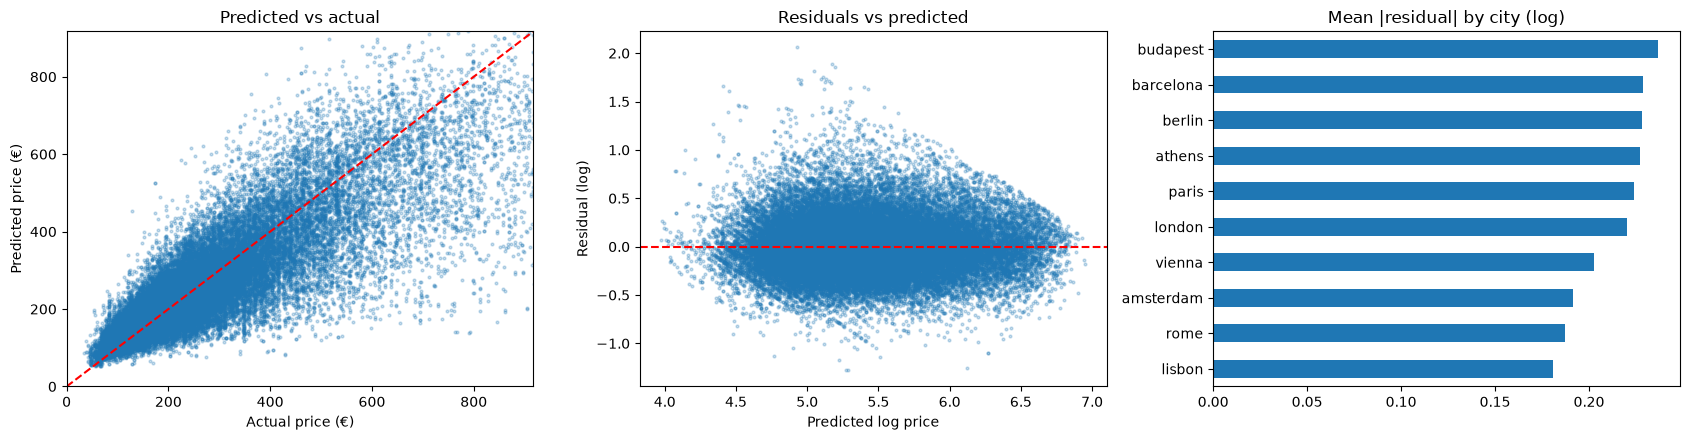

In [14]:
res = y.values - oof
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ax[0].scatter(actual, pred, s=4, alpha=0.25)
lim = [0, np.percentile(actual, 99)]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set(xlabel="Actual price (€)", ylabel="Predicted price (€)", title="Predicted vs actual")

ax[1].scatter(oof, res, s=4, alpha=0.25); ax[1].axhline(0, color="r", ls="--")
ax[1].set(xlabel="Predicted log price", ylabel="Residual (log)", title="Residuals vs predicted")

pd.Series(res, index=data["city"].values).groupby(level=0).apply(lambda s: np.abs(s).mean()) \
  .sort_values().plot.barh(ax=ax[2], title="Mean |residual| by city (log)")
plt.tight_layout(); plt.show()

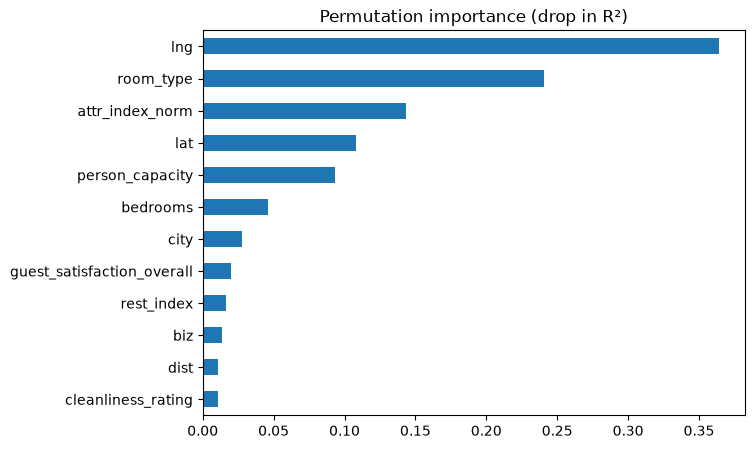

holdout R²: 0.749


In [15]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.inspection import permutation_importance

tr, te = next(GroupShuffleSplit(test_size=0.2, random_state=42).split(X, y, groups))
m = HistGradientBoostingRegressor(**search.best_params_, random_state=42).fit(X.iloc[tr], y.iloc[tr])
pi = permutation_importance(m, X.iloc[te], y.iloc[te], n_repeats=10, random_state=42, n_jobs=-1)

imp = pd.Series(pi.importances_mean, X.columns)
# merge one-hot columns back into their original feature
imp = imp.groupby(lambda c: "city" if c.startswith("city_")
                  else "room_type" if c.startswith("room_type_") else c).sum()
imp.sort_values().tail(12).plot.barh(figsize=(7, 5), title="Permutation importance (drop in R²)")
plt.show()
print("holdout R²:", round(m.score(X.iloc[te], y.iloc[te]), 3))

In [16]:
out = data.drop(columns=["log_price"]).copy().reset_index(drop=True)

# readable labels for slicers
out["city"] = out["city"].str.title()
out["day_type"] = out["is_weekend"].map({0: "Weekday", 1: "Weekend"})
for c in out.select_dtypes("bool").columns:
    out[c] = out[c].map({True: "Yes", False: "No"})

# model results (out-of-fold, so honest predictions)
out["predicted_price"] = np.expm1(oof).round(2)
out["error_eur"] = (out["predicted_price"] - out["realSum"]).round(2)
out["abs_error_eur"] = out["error_eur"].abs()
out["pct_error"] = (out["abs_error_eur"] / out["realSum"]).round(4)

out.to_csv("airbnb_powerbi.csv", index=False)

# small table for the importance chart
(imp.sort_values(ascending=False).rename("importance")
    .rename_axis("feature").reset_index().to_csv("feature_importance.csv", index=False))
print(out.shape)

(51189, 26)
